# Deep Learning Project : Prédiction de réclamation en assurance Auto

##  Exploration des Données

In [85]:
# Importation des bibliothèques 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

df = pd.read_csv('Car_Insurance_Claim-2.csv')

print(df.head())

       ID    AGE  GENDER      RACE DRIVING_EXPERIENCE    EDUCATION  \
0  569520    65+  female  majority               0-9y  high school   
1  750365  16-25    male  majority               0-9y         none   
2  199901  16-25  female  majority               0-9y  high school   
3  478866  16-25    male  majority               0-9y   university   
4  731664  26-39    male  majority             10-19y         none   

          INCOME  CREDIT_SCORE  VEHICLE_OWNERSHIP VEHICLE_YEAR  MARRIED  \
0    upper class      0.629027                1.0   after 2015      0.0   
1        poverty      0.357757                0.0  before 2015      0.0   
2  working class      0.493146                1.0  before 2015      0.0   
3  working class      0.206013                1.0  before 2015      0.0   
4  working class      0.388366                1.0  before 2015      0.0   

   CHILDREN  POSTAL_CODE  ANNUAL_MILEAGE VEHICLE_TYPE  SPEEDING_VIOLATIONS  \
0       1.0        10238         12000.0        se

Notre variable à expliquer est la variable OUTCOME qui ne prend que les modalités 0 (pas de réclamation) ou 1 (réclamation).

In [86]:
df.shape

(10000, 19)

Nous avons donc 10000 lignes et 19 colonnes dont 17 variables explicatives et la variable ID.




### Statistiques Descriptives :

In [87]:
# Statistiques descriptives
print(df.describe())

                  ID  CREDIT_SCORE  VEHICLE_OWNERSHIP       MARRIED  \
count   10000.000000   9018.000000       10000.000000  10000.000000   
mean   500521.906800      0.515813           0.697000      0.498200   
std    290030.768758      0.137688           0.459578      0.500022   
min       101.000000      0.053358           0.000000      0.000000   
25%    249638.500000      0.417191           0.000000      0.000000   
50%    501777.000000      0.525033           1.000000      0.000000   
75%    753974.500000      0.618312           1.000000      1.000000   
max    999976.000000      0.960819           1.000000      1.000000   

           CHILDREN   POSTAL_CODE  ANNUAL_MILEAGE  SPEEDING_VIOLATIONS  \
count  10000.000000  10000.000000     9043.000000         10000.000000   
mean       0.688800  19864.548400    11697.003207             1.482900   
std        0.463008  18915.613855     2818.434528             2.241966   
min        0.000000  10238.000000     2000.000000             0.

Les statistiques descriptives calculées pour les variables numériques telles que CREDIT_SCORE, ANNUAL_MILEAGE, et PAST_ACCIDENTS, mettent en évidence leurs distributions respectives. Par exemple, CREDIT_SCORE présente une moyenne de 0,52 et un écart-type de 0,13 avec des valeurs comprises entre 0,05 et 0,96. Cela traduit donc une légère variabilité mais une concentration principalement autour de la moyenne.

In [88]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  str    
 2   GENDER               10000 non-null  str    
 3   RACE                 10000 non-null  str    
 4   DRIVING_EXPERIENCE   10000 non-null  str    
 5   EDUCATION            10000 non-null  str    
 6   INCOME               10000 non-null  str    
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  str    
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE       9043 non-null   float64
 14  VEHICLE_TYPE         10000 non-null  str    
 15  SPEEDING_VIOLATIONS  10000 non-null  int64  
 16

In [89]:
# Distribution des variables catégoriques
print(df['GENDER'].value_counts())
print(df['VEHICLE_TYPE'].value_counts())

GENDER
female    5010
male      4990
Name: count, dtype: int64
VEHICLE_TYPE
sedan         9523
sports car     477
Name: count, dtype: int64


On remarque la présence légèrement plus importante de femmes que d'hommes dans nos données et bien plus de sedan que de sports car

In [90]:
# Compter les occurrences des catégories
cat_stats = df.select_dtypes(include=['object']).nunique()
print(cat_stats)


AGE                   4
GENDER                2
RACE                  2
DRIVING_EXPERIENCE    4
EDUCATION             3
INCOME                4
VEHICLE_YEAR          2
VEHICLE_TYPE          2
dtype: int64


C:\Users\free\AppData\Local\Temp\ipykernel_15216\127223642.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_stats = df.select_dtypes(include=['object']).nunique()


### Visualisations

<Axes: title={'center': 'Outcome'}, xlabel='OUTCOME', ylabel='count'>

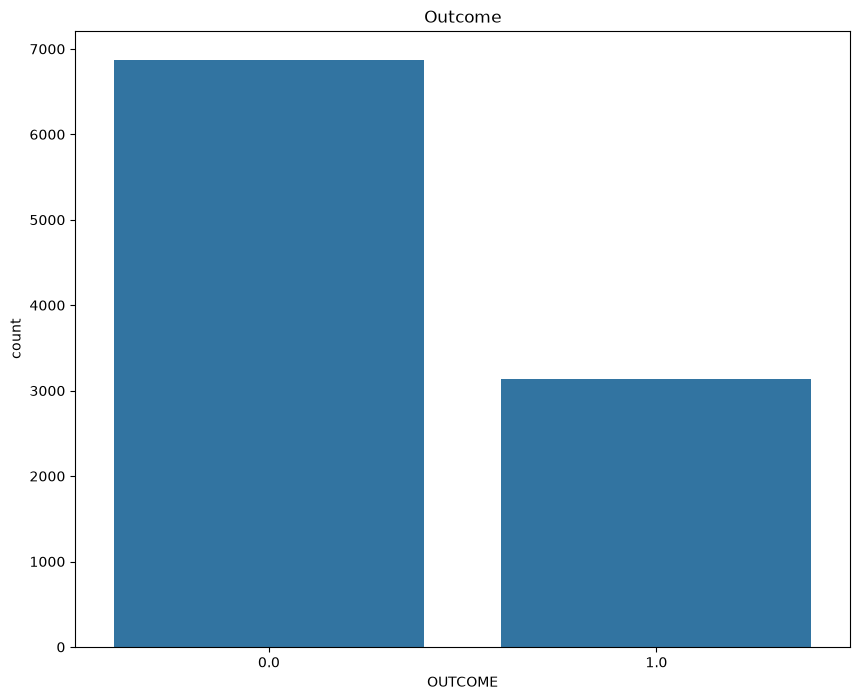

In [91]:
plt.figure(figsize=(10,8))
plt.title('Outcome')
sns.countplot(data=df, x ='OUTCOME')

Comme on peut l'observer notre base de données présente un deséquilibre naturel, on a moins de réclamation (1) que de non réclamation (0), environ le double.

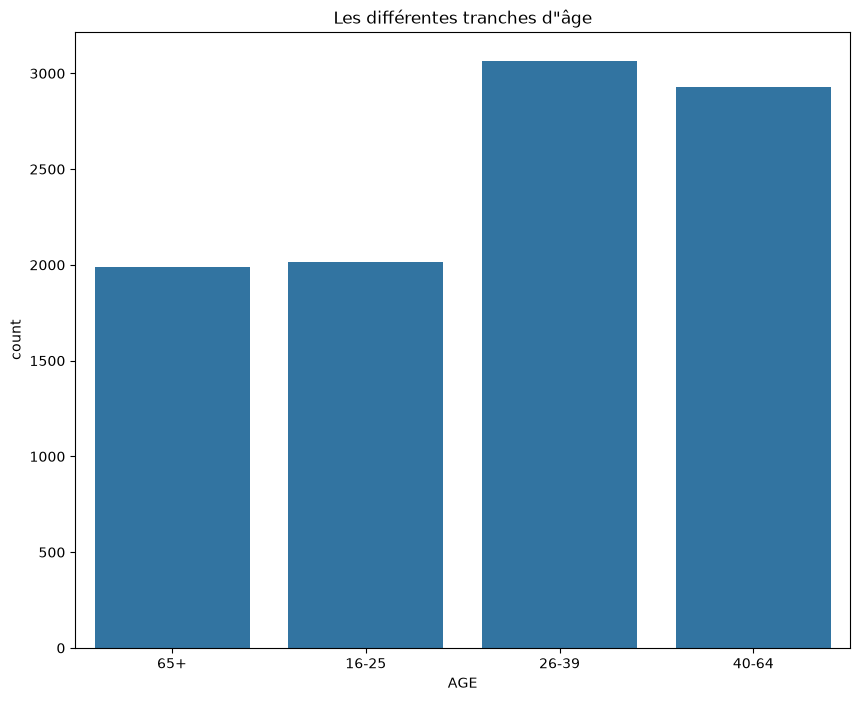

In [92]:
plt.figure(figsize=(10,8))
plt.title('Les différentes tranches d"âge')
sns.countplot(data=df, x ='AGE');

Les classes d'âges dominantes sont (26-39) et (40-64), l'âge pourrait pourrait avoir un impact sur la variable de réclamation.

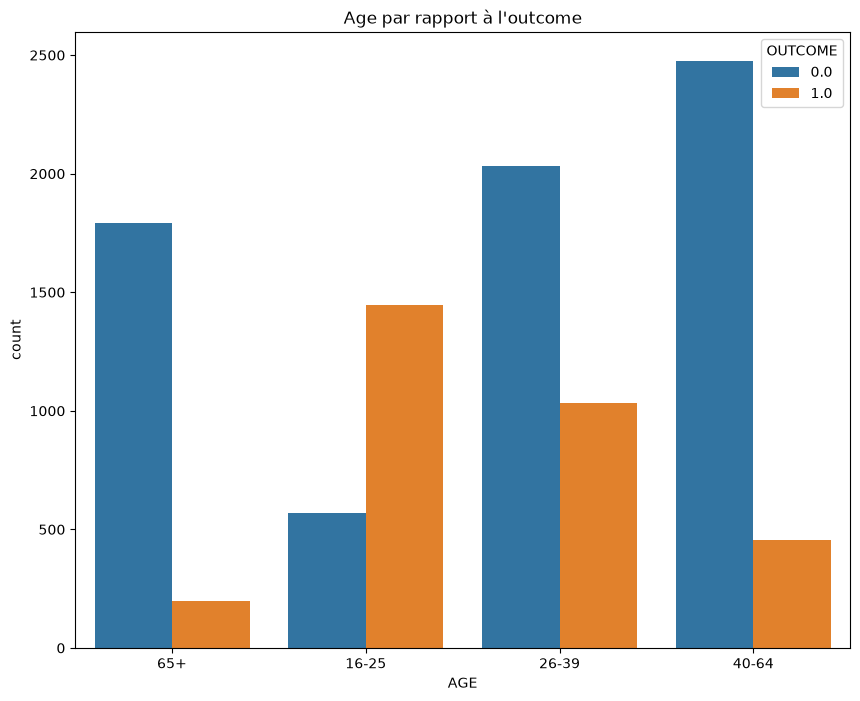

In [93]:
plt.figure(figsize=(10,8))
plt.title("Age par rapport à l'outcome")
sns.countplot(data=df, x ='AGE', hue='OUTCOME');

La répartition des réclamations en fonction des tranches d'âges montrent que les individus (jeunes) entre (16-25) présentent plus de réclamations que de non réclamations alors que pour toutes les autres tranches le nombre de réclamation ne dépasse pas les non réclamations.

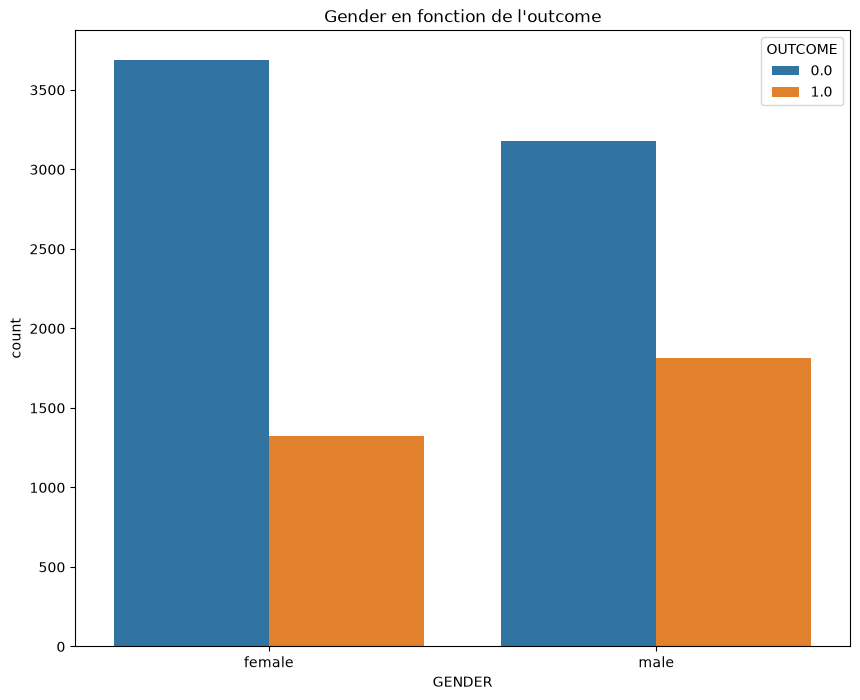

In [94]:
plt.figure(figsize=(10,8))
plt.title("Gender en fonction de l'outcome")
sns.countplot(data=df, x ='GENDER', hue='OUTCOME');

On avait vu précédemment qu'il y avait plus de femmes dans notre base de données que d'hommes mais, on observe que la proportion d'hommes présentant des réclamations par rapport aux nombres d'hommes total est plus importante que la proportion de femmes qui ont des réclamations.

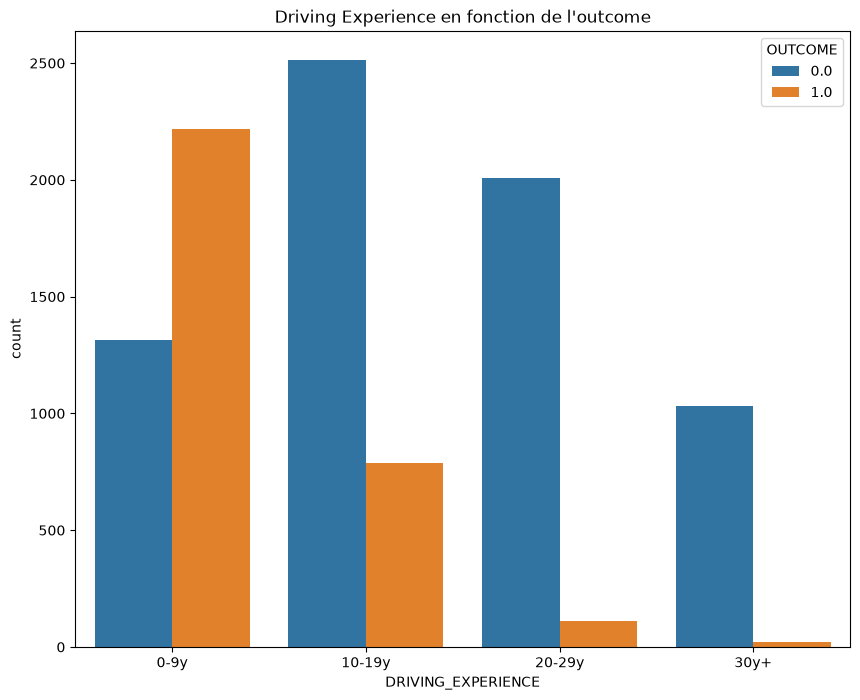

In [95]:
plt.figure(figsize=(10,8))
plt.title("Driving Experience en fonction de l'outcome")
sns.countplot(data=df, x ='DRIVING_EXPERIENCE', hue='OUTCOME');

Les individus les moins expérimentés présentes le plus de réclamations alors que le nombre réclamations décroit avec le nombre d'année d'expérience.

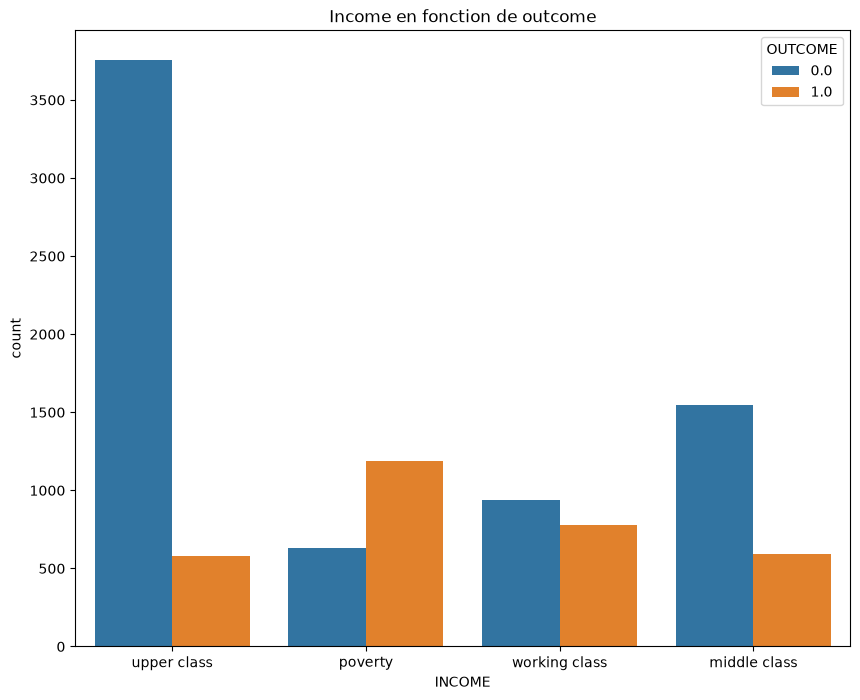

In [96]:
plt.figure(figsize=(10,8))
plt.title('Income en fonction de outcome')
sns.countplot(data=df, x ='INCOME', hue='OUTCOME');

Pour INCOME, les classes poverty et working class présentent le plus de réclamation par rapport aux nombres d'individus dans la classe.

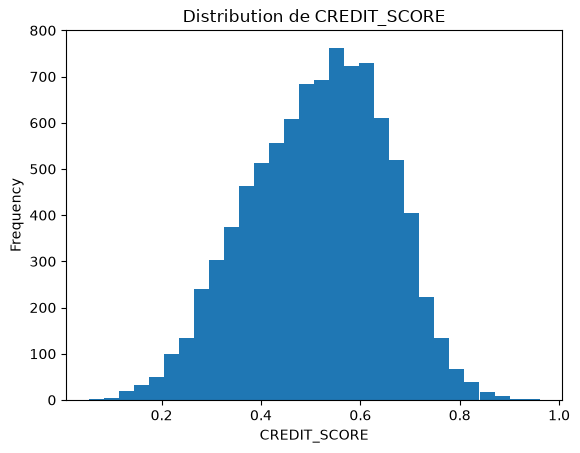

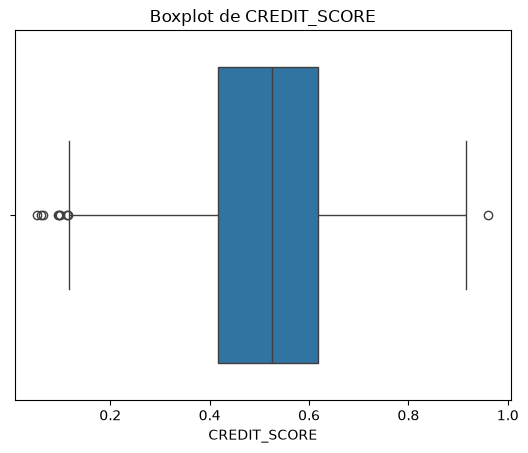

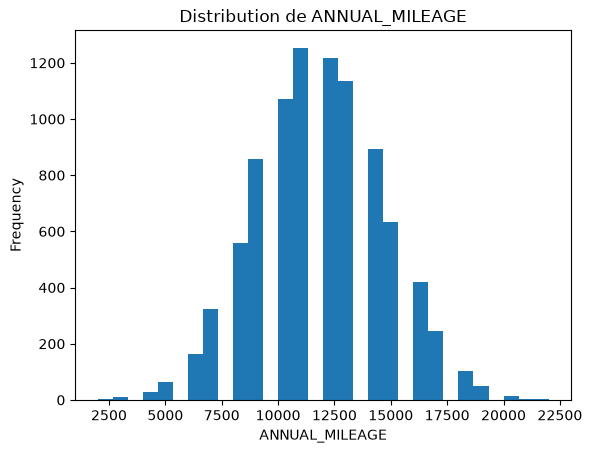

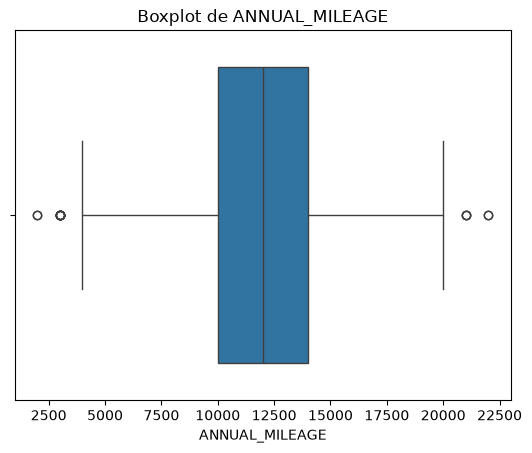

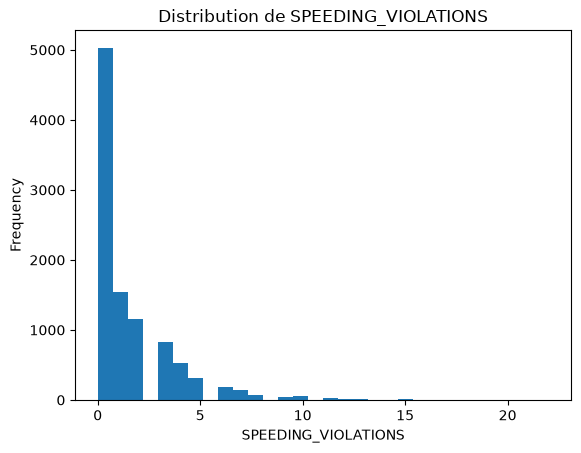

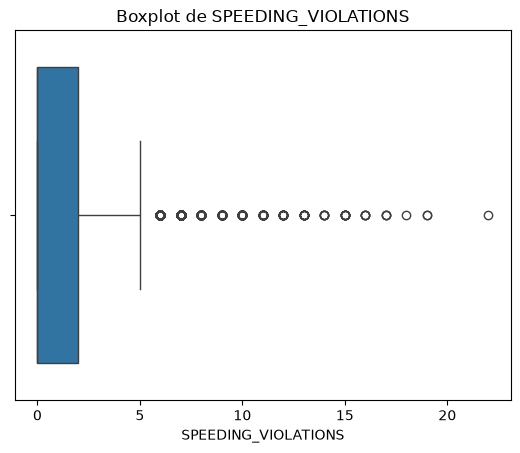

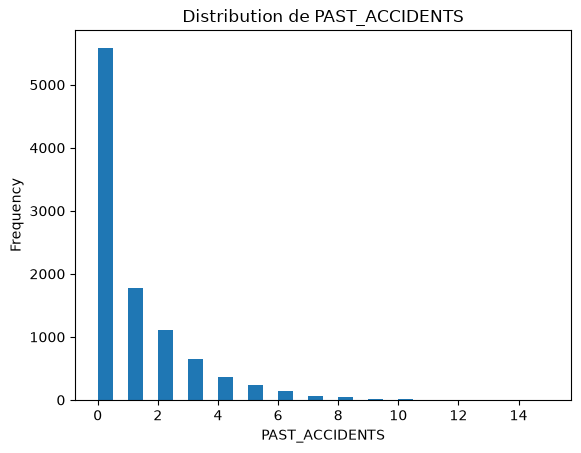

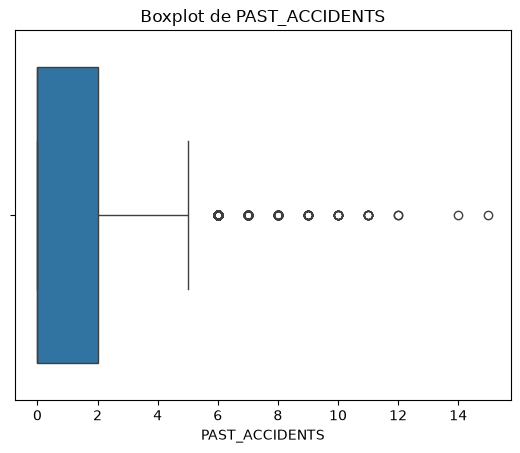

In [97]:
var_num = ['CREDIT_SCORE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'PAST_ACCIDENTS']

# Boucle pour créer des histogrammes et des boxplots
for column in var_num:
    # Histogramme
    df[column].plot(kind='hist', bins=30, title=f'Distribution de {column}')
    plt.xlabel(column)
    plt.show()

    # Boxplot
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot de {column}')
    plt.show()



In [98]:
#pip install geopandas

In [99]:
import os
import json
import urllib.request

# Télécharger et sauvegarder le fichier GeoJSON localement
geojson_path = 'departements-france.geojson'
geojson_url = 'https://github.com/gregoiredavid/france-geojson/raw/master/departements-version-simplifiee.geojson'

if not os.path.exists(geojson_path):
    try:
        print(f"Téléchargement du fichier GeoJSON...")
        urllib.request.urlretrieve(geojson_url, geojson_path)
        print(f"✓ Fichier sauvegardé: {geojson_path}")
    except Exception as e:
        print(f"✗ Erreur lors du téléchargement: {e}")
else:
    print(f"✓ Le fichier {geojson_path} existe déjà")

✓ Le fichier departements-france.geojson existe déjà


Cette carte nous permet d'observer la répartition des réclamations en fonction des différents départements. Notre base de données concerne uniquement quatre départements : 10, 32, 92 et 21.  Une carte a été créée pour visualiser la répartition des réclamations (OUTCOME = 1) dans ces départements, permettant de mettre en évidence les zones où le nombre de réclamations est le plus élevé. Cependant, cette visualisation n'est pas très pertinente car le jeu de données est biaisé : les proportions des données ne sont pas équitablement réparties entre les départements. Cela fausse l'interprétation, rendant difficile l'évaluation d'une tendance réelle ou l'identification de facteurs explicatifs à partir de la seule variable géographique.

In [100]:
import geopandas as gpd
import plotly.express as px

# Données
df['DEPARTMENT'] = (
    df['POSTAL_CODE']
    .astype(str)
    .str.zfill(5)
    .str[:2]
)

outcome_counts = (
    df[df['OUTCOME'] == 1]
    .groupby('DEPARTMENT')
    .size()
    .reset_index(name='COUNT')
)

# Carte
france_map = gpd.read_file(geojson_path)
france_map['DEPARTMENT'] = france_map['code'].astype(str).str[:2]

# Fusion
merged_map = france_map.merge(
    outcome_counts,
    on='DEPARTMENT',
    how='left'
)

merged_map['COUNT'] = merged_map['COUNT'].fillna(0)

# GeoJSON
geojson = merged_map.__geo_interface__

# Carte
fig = px.choropleth_map(
    merged_map,
    geojson=geojson,
    locations='DEPARTMENT',
    featureidkey='properties.DEPARTMENT',
    color='COUNT',
    hover_name='DEPARTMENT',
    color_continuous_scale='OrRd',
    map_style='carto-positron',
    center={"lat": 46.603354, "lon": 1.888334},
    zoom=5,
    title="Nombre de réclamations par département"
)

fig.update_layout(
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)

fig.show()

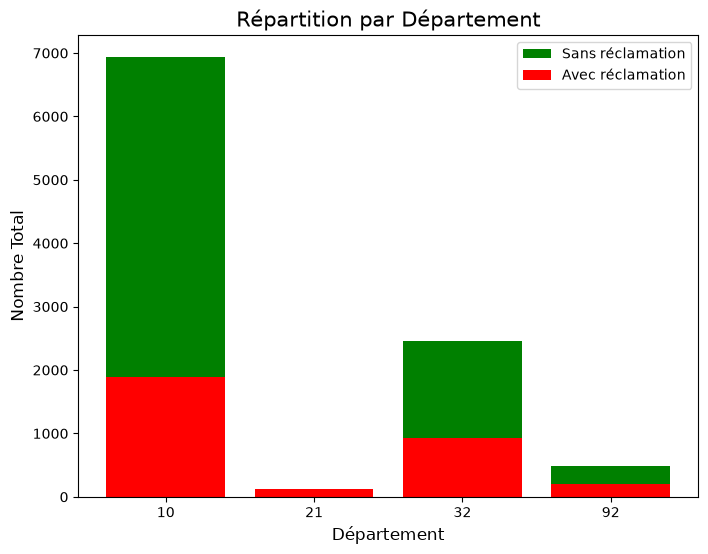

In [101]:
# Préparer les données
total_counts = df.groupby('DEPARTMENT').size().reset_index(name='TOTAL')
merged_counts = outcome_counts.merge(total_counts, on='DEPARTMENT')
merged_counts['OTHER'] = merged_counts['TOTAL'] - merged_counts['COUNT']

# Tracer un diagramme empilé
plt.figure(figsize=(8, 6))
plt.bar(merged_counts['DEPARTMENT'], merged_counts['OTHER'], bottom=merged_counts['COUNT'], label='Sans réclamation', color='GREEN')
plt.bar(merged_counts['DEPARTMENT'], merged_counts['COUNT'], label='Avec réclamation', color='red')
plt.xlabel("Département", fontsize=12)
plt.ylabel("Nombre Total", fontsize=12)
plt.title("Répartition par Département", fontsize=15)
plt.legend(fontsize=10)
plt.show()


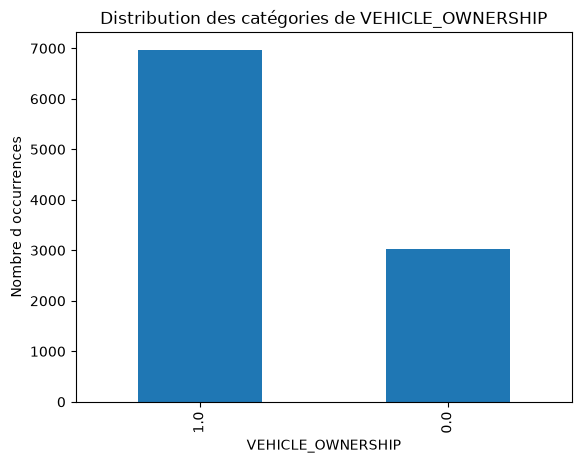

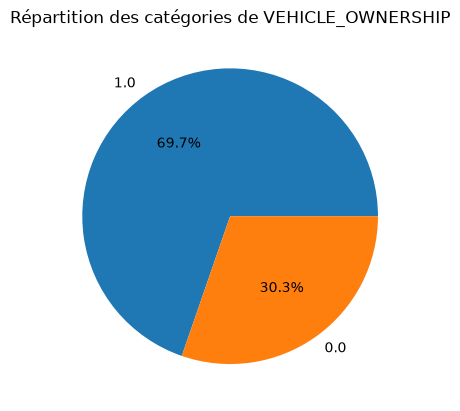

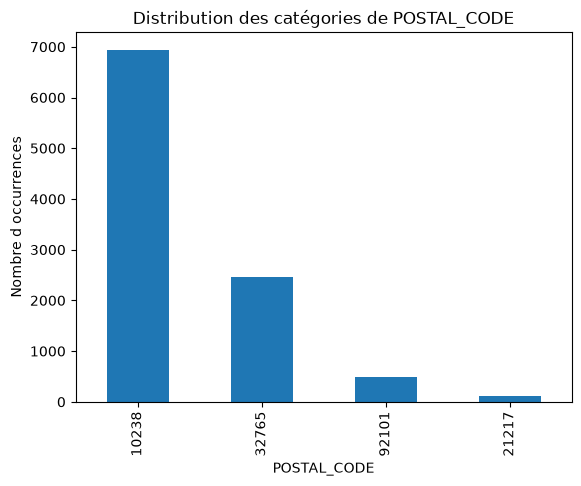

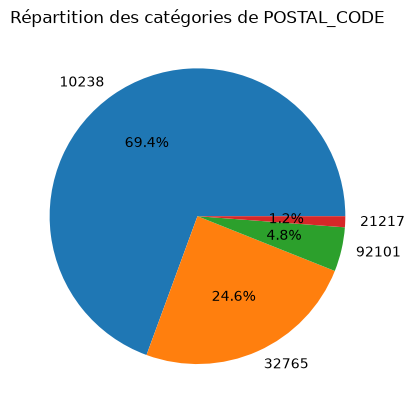

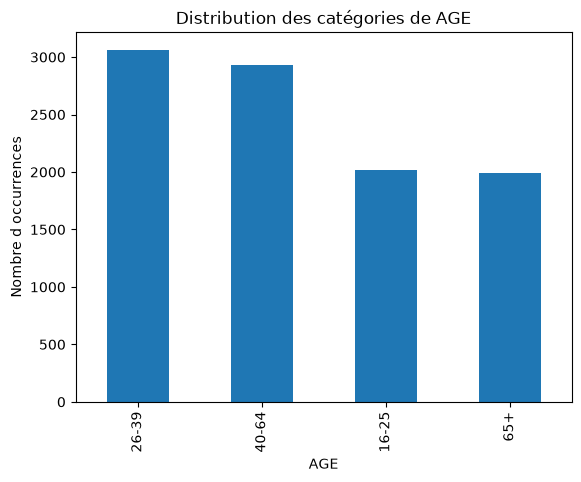

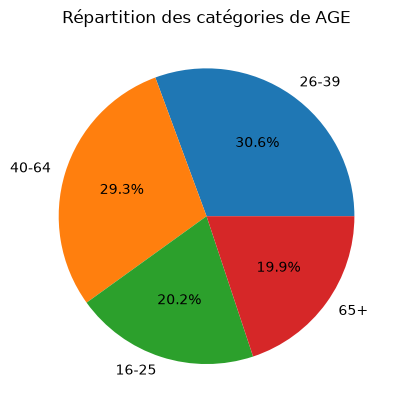

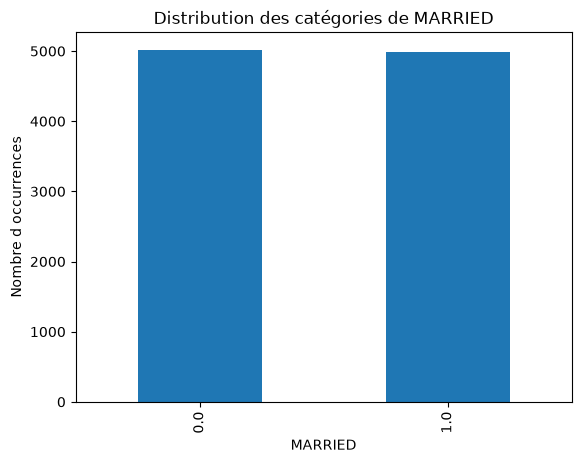

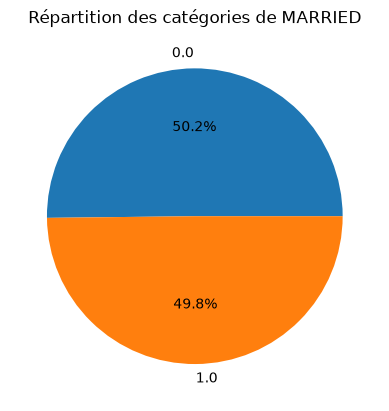

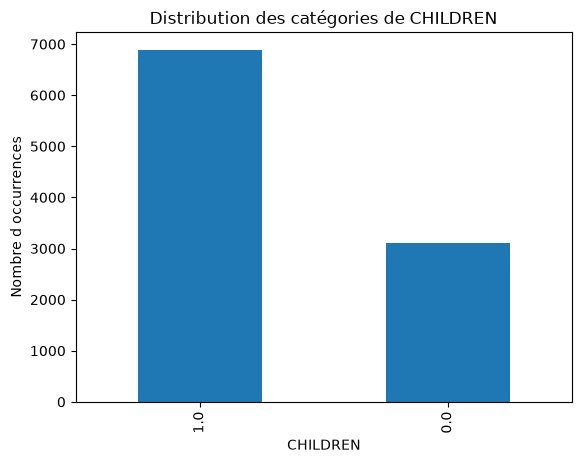

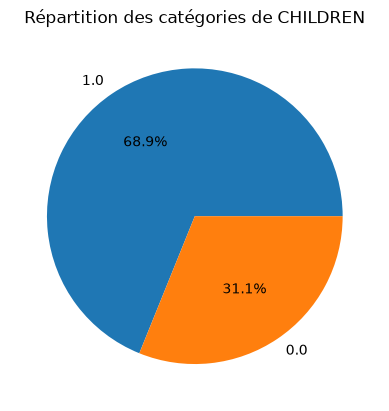

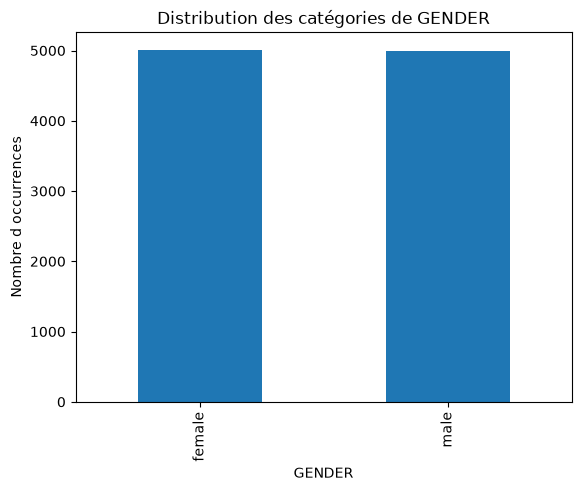

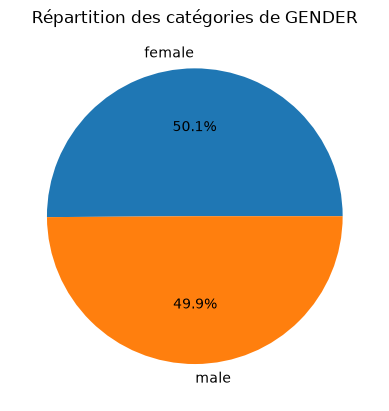

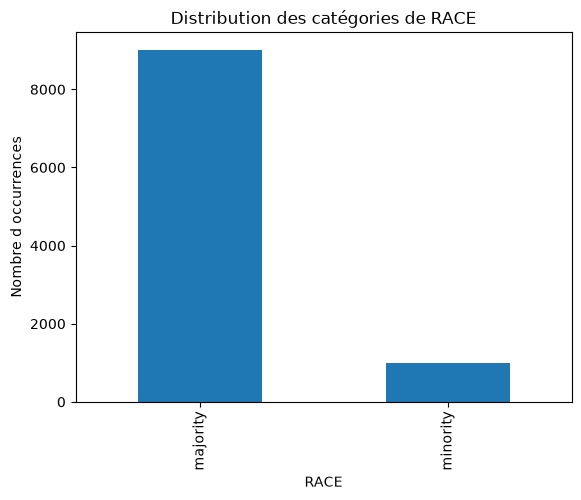

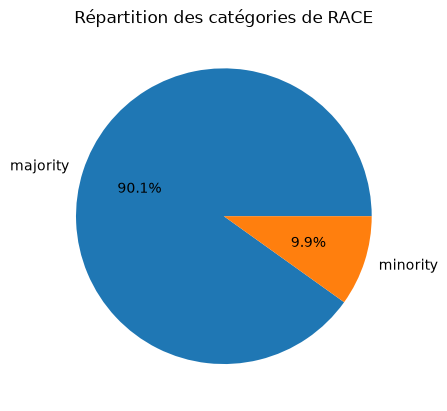

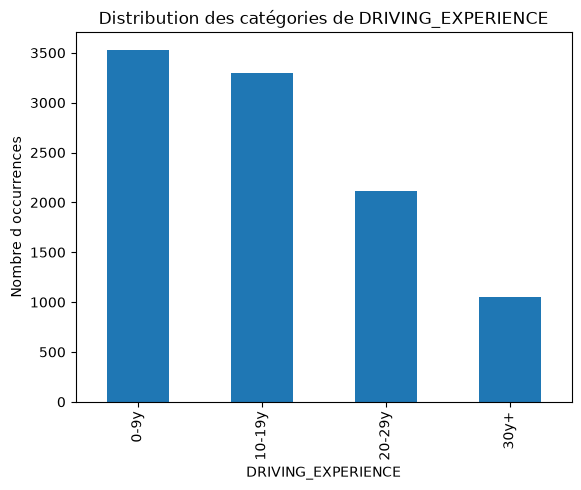

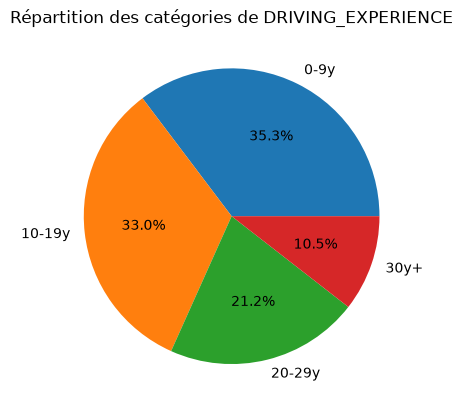

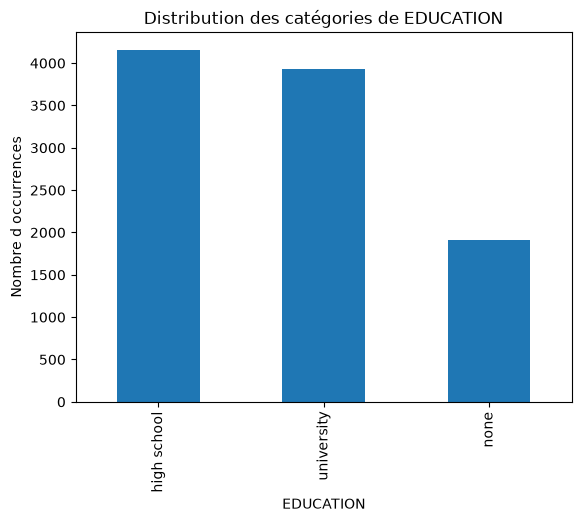

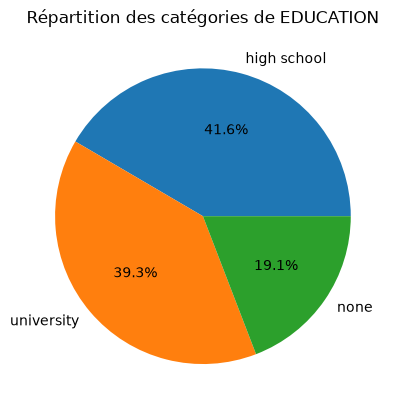

In [102]:

var_categ = ['VEHICLE_OWNERSHIP', 'POSTAL_CODE', 'AGE', 'MARRIED', 'CHILDREN', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION']

# Boucle pour générer des bar charts et des pie charts
for column in var_categ:
    # Bar chart
    value_counts = df[column].value_counts()
    value_counts.plot(kind='bar', title=f'Distribution des catégories de {column}')
    plt.xlabel(column)
    plt.ylabel('Nombre d occurrences')
    plt.show()

    # Pie chart
    value_counts.plot(kind='pie', autopct='%1.1f%%', title=f'Répartition des catégories de {column}')
    plt.ylabel('')  # Supprime le label par défaut
    plt.show()


In [103]:
#!pip install sweetviz

In [104]:
#import sweetviz as sv

# Analyse des données par rapport à la target
#report = sv.analyze(df, target_feat='OUTCOME')

# Génération du rapport interactif
#report.show_html("rapport_sweetviz.html")

##  Nettoyage des données et Analyse des corélations

In [105]:
print(df['OUTCOME'].value_counts())

OUTCOME
0.0    6867
1.0    3133
Name: count, dtype: int64


On a 3133 réclamations pour 10000 lignes, donc à peu près 31%.

Séparation immédiate des données (Anti-Data Leakage) : On isole 20 % des données qui représenteront "le jeu de test. On applique également une stratification (stratify=y) car les sinistres sont plus rares environs 30% : cela garantit qu'on aura la même proportion de sinistres dans le Train et dans le Test.

### Analyse des valeurs manquantes et  Traitement des Incohérences :

In [106]:
X = df.drop(columns=['OUTCOME', 'ID'])
y = df['OUTCOME']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [107]:
print(df.isnull().sum())

# Calcul du pourcentage de valeurs manquantes
missing_credit_score = df['CREDIT_SCORE'].isnull().sum() / len(df) * 100
missing_annual_mileage = df['ANNUAL_MILEAGE'].isnull().sum() / len(df) * 100

print(f"Pourcentage de valeurs manquantes dans CREDIT_SCORE : {missing_credit_score:.2f}%")
print(f"Pourcentage de valeurs manquantes dans ANNUAL_MILEAGE : {missing_annual_mileage:.2f}%")


ID                       0
AGE                      0
GENDER                   0
RACE                     0
DRIVING_EXPERIENCE       0
EDUCATION                0
INCOME                   0
CREDIT_SCORE           982
VEHICLE_OWNERSHIP        0
VEHICLE_YEAR             0
MARRIED                  0
CHILDREN                 0
POSTAL_CODE              0
ANNUAL_MILEAGE         957
VEHICLE_TYPE             0
SPEEDING_VIOLATIONS      0
DUIS                     0
PAST_ACCIDENTS           0
OUTCOME                  0
DEPARTMENT               0
dtype: int64
Pourcentage de valeurs manquantes dans CREDIT_SCORE : 9.82%
Pourcentage de valeurs manquantes dans ANNUAL_MILEAGE : 9.57%


Nous avons des valeurs manquantes pour les variables CREDIT_SCORE et ANNUAL_MILEAGE, ce qui nous fait un total de 1939 Valeurs manquantes,pour chacune de ces deux variables on a moins de 10% de valeurs manquantes, donc une simple imputation est préférable.

Pour analyser les valaurs manquantes on va visualiser la distribution des valeurs existantes tout d'abord.

Valeurs manquantes pour CREDIT_SCORE : 982
Valeurs manquantes pour ANNUAL_MILEAGE : 957


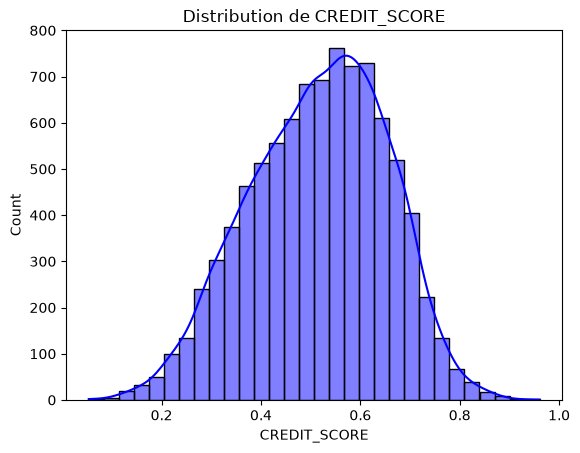

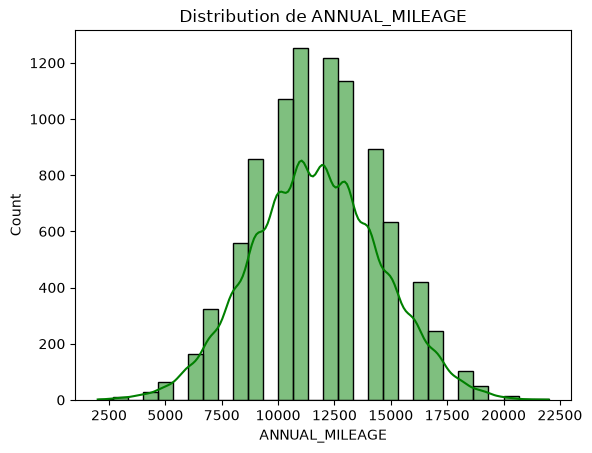

In [108]:
missing_credit_score = df['CREDIT_SCORE'].isnull().sum()
missing_annual_mileage = df['ANNUAL_MILEAGE'].isnull().sum()

print(f"Valeurs manquantes pour CREDIT_SCORE : {missing_credit_score}")
print(f"Valeurs manquantes pour ANNUAL_MILEAGE : {missing_annual_mileage}")


sns.histplot(df['CREDIT_SCORE'], kde=True, bins=30, color='blue')
plt.title('Distribution de CREDIT_SCORE')
plt.show()

sns.histplot(df['ANNUAL_MILEAGE'], kde=True, bins=30, color='green')
plt.title('Distribution de ANNUAL_MILEAGE')
plt.show()


La distribution de CREDIT_SCORE est plus ou moins asymétrique. Cette variable peut être influencée par des valeurs aberrantes (scores très faibles ou très élevés). Nous allons donc utiliser la médiane pour minimiser leur impact.

<Axes: title={'center': 'Boxplot of Credit Score'}, xlabel='CREDIT_SCORE'>

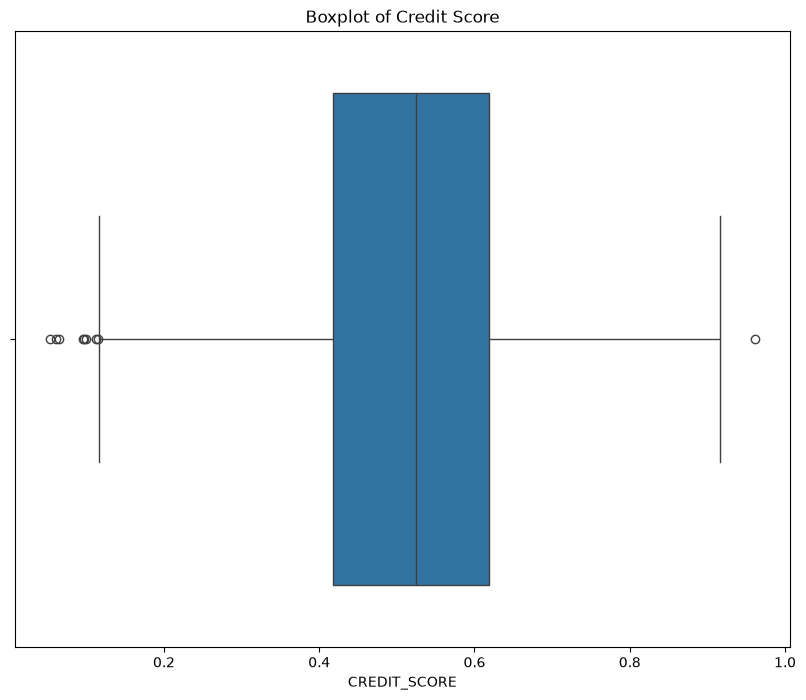

In [109]:
plt.figure(figsize=(10,8))
plt.title('Boxplot of Credit Score')
sns.boxplot(data=df, x='CREDIT_SCORE')

<Axes: title={'center': 'Boxplot of ANNUAL_MILEAGE'}, xlabel='ANNUAL_MILEAGE'>

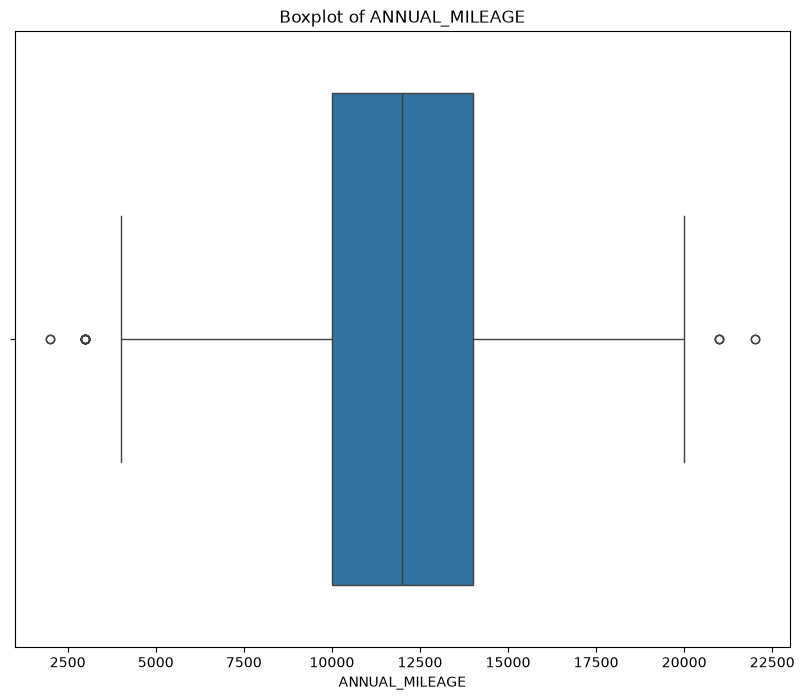

In [110]:
plt.figure(figsize=(10,8))
plt.title('Boxplot of ANNUAL_MILEAGE')
sns.boxplot(data=df, x='ANNUAL_MILEAGE')

ANNUAL_MILEAGE peut avoir une distribution proche de la normale, surtout si les valeurs extrêmes sont rares comme le montre le boxplot. Le kilométrage annuel suit généralement une distribution assez stable et homogène. Ainsi, pour ANNUAL_MILEAGE, nous allons utiliser la moyenne pour remplacer les valeurs manquantes. On applique directement cette imputation aux données d'entrainement.

In [111]:
median_credit = X_train['CREDIT_SCORE'].median()
mean_mileage = X_train['ANNUAL_MILEAGE'].mean()

X_train['CREDIT_SCORE'] = X_train['CREDIT_SCORE'].fillna(median_credit)
X_train['ANNUAL_MILEAGE'] = X_train['ANNUAL_MILEAGE'].fillna(mean_mileage)

X_test['CREDIT_SCORE'] = X_test['CREDIT_SCORE'].fillna(median_credit)
X_test['ANNUAL_MILEAGE'] = X_test['ANNUAL_MILEAGE'].fillna(mean_mileage)

In [112]:
X_train.isnull().sum()

AGE                    0
GENDER                 0
RACE                   0
DRIVING_EXPERIENCE     0
EDUCATION              0
INCOME                 0
CREDIT_SCORE           0
VEHICLE_OWNERSHIP      0
VEHICLE_YEAR           0
MARRIED                0
CHILDREN               0
POSTAL_CODE            0
ANNUAL_MILEAGE         0
VEHICLE_TYPE           0
SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
DEPARTMENT             0
dtype: int64

In [113]:
X_test.isnull().sum()

AGE                    0
GENDER                 0
RACE                   0
DRIVING_EXPERIENCE     0
EDUCATION              0
INCOME                 0
CREDIT_SCORE           0
VEHICLE_OWNERSHIP      0
VEHICLE_YEAR           0
MARRIED                0
CHILDREN               0
POSTAL_CODE            0
ANNUAL_MILEAGE         0
VEHICLE_TYPE           0
SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
DEPARTMENT             0
dtype: int64

Observons à nouveau la distribution de nos variables.

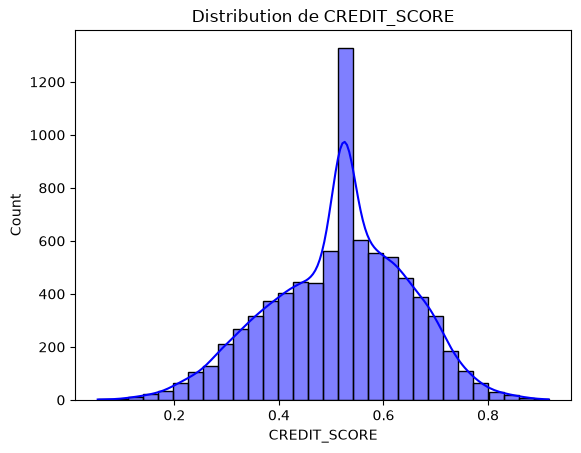

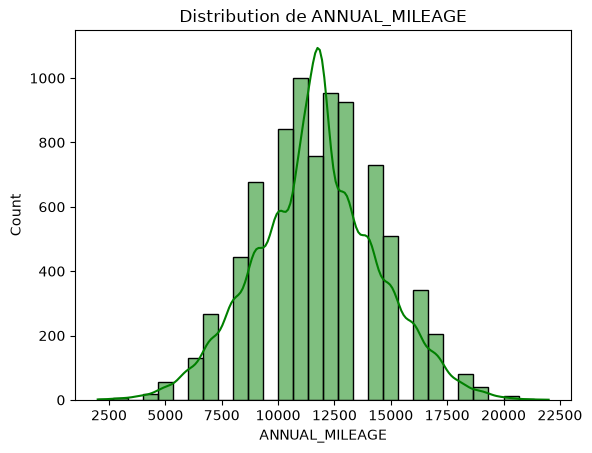

In [114]:
sns.histplot(X_train['CREDIT_SCORE'], kde=True, bins=30, color='blue')
plt.title('Distribution de CREDIT_SCORE')
plt.show()

sns.histplot(X_train['ANNUAL_MILEAGE'], kde=True, bins=30, color='green')
plt.title('Distribution de ANNUAL_MILEAGE')
plt.show()

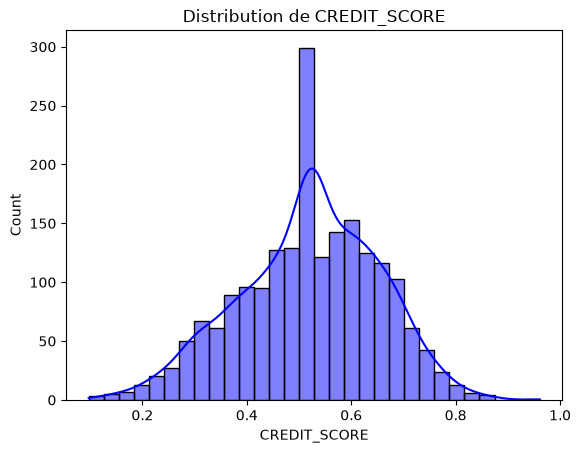

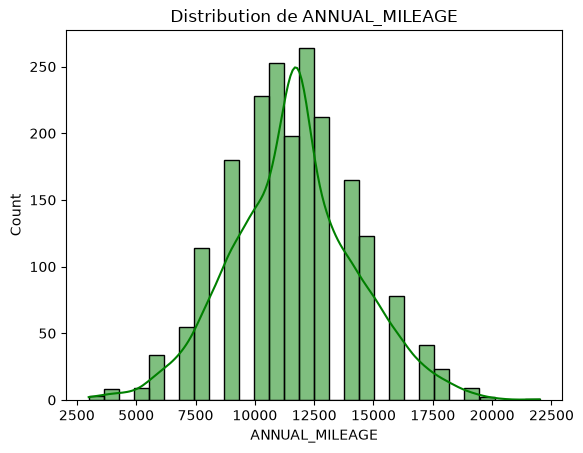

In [115]:
# Visualiser la distribution des valeurs existantes
sns.histplot(X_test['CREDIT_SCORE'], kde=True, bins=30, color='blue')
plt.title('Distribution de CREDIT_SCORE')
plt.show()

sns.histplot(X_test['ANNUAL_MILEAGE'], kde=True, bins=30, color='green')
plt.title('Distribution de ANNUAL_MILEAGE')
plt.show()

Nous remarquons que l'imputation par la médiane de CREDIT_SCORE créé un biais avec un pic aux environs de 0.5 dans la distribution  de cette dernière alors que pour ANNUAL_MILEAGE, la distribution est relativement identique. Ainsi, nous allons utiliser la variable INCOME pour l'imputation des valeurs manquantes de CREDIT_SCORE, car ces deux variables sont étroitement liées. Le niveau de revenu influence souvent la gestion financière d'un individu, ce qui se reflète directement dans son score de crédit. En s'appuyant sur les groupes de revenus pour estimer les valeurs manquantes, cette approche garantit une estimation plus réaliste avec les tendances observées, tout en préservant la structure naturelle des données et en minimisant les biais potentiels liés à une imputation globale.

On reprend nos données avant imputation: 

In [116]:
X = df.drop(columns=['OUTCOME', 'ID'])
y = df['OUTCOME']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [117]:
# On garde la même imputation pour annuel mileage
mean_mileage = X_train['ANNUAL_MILEAGE'].mean()
X_train['ANNUAL_MILEAGE'] = X_train['ANNUAL_MILEAGE'].fillna(mean_mileage)
X_test['ANNUAL_MILEAGE'] = X_test['ANNUAL_MILEAGE'].fillna(mean_mileage)

Valeurs manquantes dans X_train après imputation : 0
Valeurs manquantes dans X_test après imputation : 0


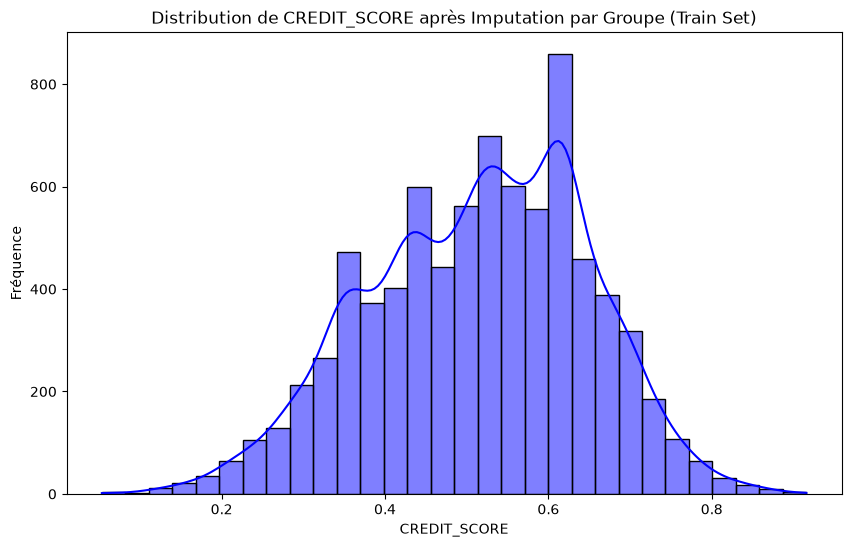

In [118]:
# Calcul des médianes par groupe UNIQUEMENT sur le jeu d'entraînement (X_train)
upper_class_median = X_train[X_train['INCOME'] == 'upper class']['CREDIT_SCORE'].median()
middle_class_median = X_train[X_train['INCOME'] == 'middle class']['CREDIT_SCORE'].median()
poverty_class_median = X_train[X_train['INCOME'] == 'poverty']['CREDIT_SCORE'].median()
working_class_median = X_train[X_train['INCOME'] == 'working class']['CREDIT_SCORE'].median()


# Remplissage des valeurs manquantes dans le jeu d'ENTRAÎNEMENT (X_train)
X_train.loc[(X_train['INCOME'] == 'upper class') & (X_train['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = upper_class_median
X_train.loc[(X_train['INCOME'] == 'middle class') & (X_train['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = middle_class_median
X_train.loc[(X_train['INCOME'] == 'poverty') & (X_train['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = poverty_class_median
X_train.loc[(X_train['INCOME'] == 'working class') & (X_train['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = working_class_median


# Remplissage des valeurs manquantes dans le jeu de TEST (X_test) avec les mêmes médianes
X_test.loc[(X_test['INCOME'] == 'upper class') & (X_test['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = upper_class_median
X_test.loc[(X_test['INCOME'] == 'middle class') & (X_test['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = middle_class_median
X_test.loc[(X_test['INCOME'] == 'poverty') & (X_test['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = poverty_class_median
X_test.loc[(X_test['INCOME'] == 'working class') & (X_test['CREDIT_SCORE'].isnull()), 'CREDIT_SCORE'] = working_class_median


# 4. Vérification après imputation
print("Valeurs manquantes dans X_train après imputation :", X_train['CREDIT_SCORE'].isnull().sum())
print("Valeurs manquantes dans X_test après imputation :", X_test['CREDIT_SCORE'].isnull().sum())


# 5. Visualisation de la distribution sur le Train après imputation
plt.figure(figsize=(10, 6))
sns.histplot(X_train['CREDIT_SCORE'], bins=30, kde=True, color='blue')
plt.title('Distribution de CREDIT_SCORE après Imputation par Groupe (Train Set)')
plt.xlabel('CREDIT_SCORE')
plt.ylabel('Fréquence')
plt.show()

### Validation des Types de Données :

In [119]:
#les différents types de données de chaque colonne
print(df.dtypes)


ID                       int64
AGE                        str
GENDER                     str
RACE                       str
DRIVING_EXPERIENCE         str
EDUCATION                  str
INCOME                     str
CREDIT_SCORE           float64
VEHICLE_OWNERSHIP      float64
VEHICLE_YEAR               str
MARRIED                float64
CHILDREN               float64
POSTAL_CODE              int64
ANNUAL_MILEAGE         float64
VEHICLE_TYPE               str
SPEEDING_VIOLATIONS      int64
DUIS                     int64
PAST_ACCIDENTS           int64
OUTCOME                float64
DEPARTMENT                 str
dtype: object


In [120]:
for column in df.columns:
    print(f"Colonne: {column}")
    print(df[column].unique())
    print("-" * 50)

Colonne: ID
[569520 750365 199901 ... 468409 903459 442696]
--------------------------------------------------
Colonne: AGE
<StringArray>
['65+', '16-25', '26-39', '40-64']
Length: 4, dtype: str
--------------------------------------------------
Colonne: GENDER
<StringArray>
['female', 'male']
Length: 2, dtype: str
--------------------------------------------------
Colonne: RACE
<StringArray>
['majority', 'minority']
Length: 2, dtype: str
--------------------------------------------------
Colonne: DRIVING_EXPERIENCE
<StringArray>
['0-9y', '10-19y', '20-29y', '30y+']
Length: 4, dtype: str
--------------------------------------------------
Colonne: EDUCATION
<StringArray>
['high school', 'none', 'university']
Length: 3, dtype: str
--------------------------------------------------
Colonne: INCOME
<StringArray>
['upper class', 'poverty', 'working class', 'middle class']
Length: 4, dtype: str
--------------------------------------------------
Colonne: CREDIT_SCORE
[0.62902731 0.35775712 0.

Les colonnes qualitatives, telles que ID et POSTAL_CODE vont être converties en chaînes de caractères afin d'éviter leur interprétation erronée comme des données numériques. En effet, les différentes valeurs de ces variables ne reflètent aucune hiérarchie ou relation ordinale et ne doivent pas être traitées comme telles.

Nous allons également mettre la variable Children en numérique, car il s'agit du nombre d'enfants.

In [121]:
df['ID'] = df['ID'].astype(str)
df['POSTAL_CODE'] = df['POSTAL_CODE'].astype(str)
df['CHILDREN'] = df['CHILDREN'].astype(int)

Le reste des variables étant dans un format adapté, nous allons passer a l'analyse des corélations.

### Encodage / Normalisation et  Analyse des Corrélations 

In [122]:
# Encodage des variables ordinales
mapping_age = {'16-25': 0, '26-39': 1, '40-64': 2, '65+': 3}
mapping_experience = {'0-9y': 0, '10-19y': 1, '20-29y': 2, '30y+': 3}
mapping_education = {'none': 0, 'high school': 1, 'university': 2}
mapping_income = {'poverty': 0, 'working class': 1, 'middle class': 2, 'upper class': 3}

# Application sur X_train
X_train['AGE'] = X_train['AGE'].map(mapping_age)
X_train['DRIVING_EXPERIENCE'] = X_train['DRIVING_EXPERIENCE'].map(mapping_experience)
X_train['EDUCATION'] = X_train['EDUCATION'].map(mapping_education)
X_train['INCOME'] = X_train['INCOME'].map(mapping_income)

# Application sur X_test
X_test['AGE'] = X_test['AGE'].map(mapping_age)
X_test['DRIVING_EXPERIENCE'] = X_test['DRIVING_EXPERIENCE'].map(mapping_experience)
X_test['EDUCATION'] = X_test['EDUCATION'].map(mapping_education)
X_test['INCOME'] = X_test['INCOME'].map(mapping_income)

In [123]:
from sklearn.preprocessing import OneHotEncoder

cat_columns = ['GENDER', 'VEHICLE_YEAR', 'VEHICLE_TYPE']

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded_raw = ohe.fit_transform(X_train[cat_columns])
X_test_encoded_raw = ohe.transform(X_test[cat_columns])

encoded_feature_names = ohe.get_feature_names_out(cat_columns)

X_train_encoded_df = pd.DataFrame(X_train_encoded_raw, columns=encoded_feature_names, index=X_train.index)
X_test_encoded_df = pd.DataFrame(X_test_encoded_raw, columns=encoded_feature_names, index=X_test.index)

X_train_numeric = X_train.drop(columns=cat_columns)
X_test_numeric = X_test.drop(columns=cat_columns)

X_train_final = pd.concat([X_train_numeric, X_train_encoded_df], axis=1)
X_test_final = pd.concat([X_test_numeric, X_test_encoded_df], axis=1)


print("Forme de X_train final :", X_train_final.shape)
print("Forme de X_test final :", X_test_final.shape)
X_train_final.head()

Forme de X_train final : (8000, 21)
Forme de X_test final : (2000, 21)


,AGE,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,...,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,DEPARTMENT,GENDER_female,GENDER_male,VEHICLE_YEAR_after 2015,VEHICLE_YEAR_before 2015,VEHICLE_TYPE_sedan,VEHICLE_TYPE_sports car
4875,1,minority,1,2,3,0.712351,0.0,0.0,0.0,10238,...,0,0,0,10,1.0,0.0,1.0,0.0,1.0,0.0
2191,3,majority,0,2,3,0.533479,1.0,1.0,1.0,10238,...,0,0,0,10,1.0,0.0,0.0,1.0,1.0,0.0
2271,2,minority,1,2,3,0.694596,1.0,0.0,1.0,10238,...,0,0,0,10,1.0,0.0,1.0,0.0,1.0,0.0
7184,1,majority,1,2,3,0.515658,0.0,0.0,1.0,10238,...,0,0,1,10,1.0,0.0,0.0,1.0,1.0,0.0
3910,2,majority,2,1,3,0.537726,0.0,1.0,1.0,32765,...,3,2,1,32,1.0,0.0,0.0,1.0,1.0,0.0


In [124]:
from sklearn.preprocessing import StandardScaler

col_to_scale = 'ANNUAL_MILEAGE'

scaler = StandardScaler()

X_train_final[col_to_scale] = scaler.fit_transform(X_train_final[[col_to_scale]])

X_test_final[col_to_scale] = scaler.transform(X_test_final[[col_to_scale]])

print("Moyenne après standardisation :", X_train_final[col_to_scale].mean())
print("Écart-type après standardisation :", X_train_final[col_to_scale].std())

Moyenne après standardisation : 2.2870594307278225e-16
Écart-type après standardisation : 1.0000625058599855


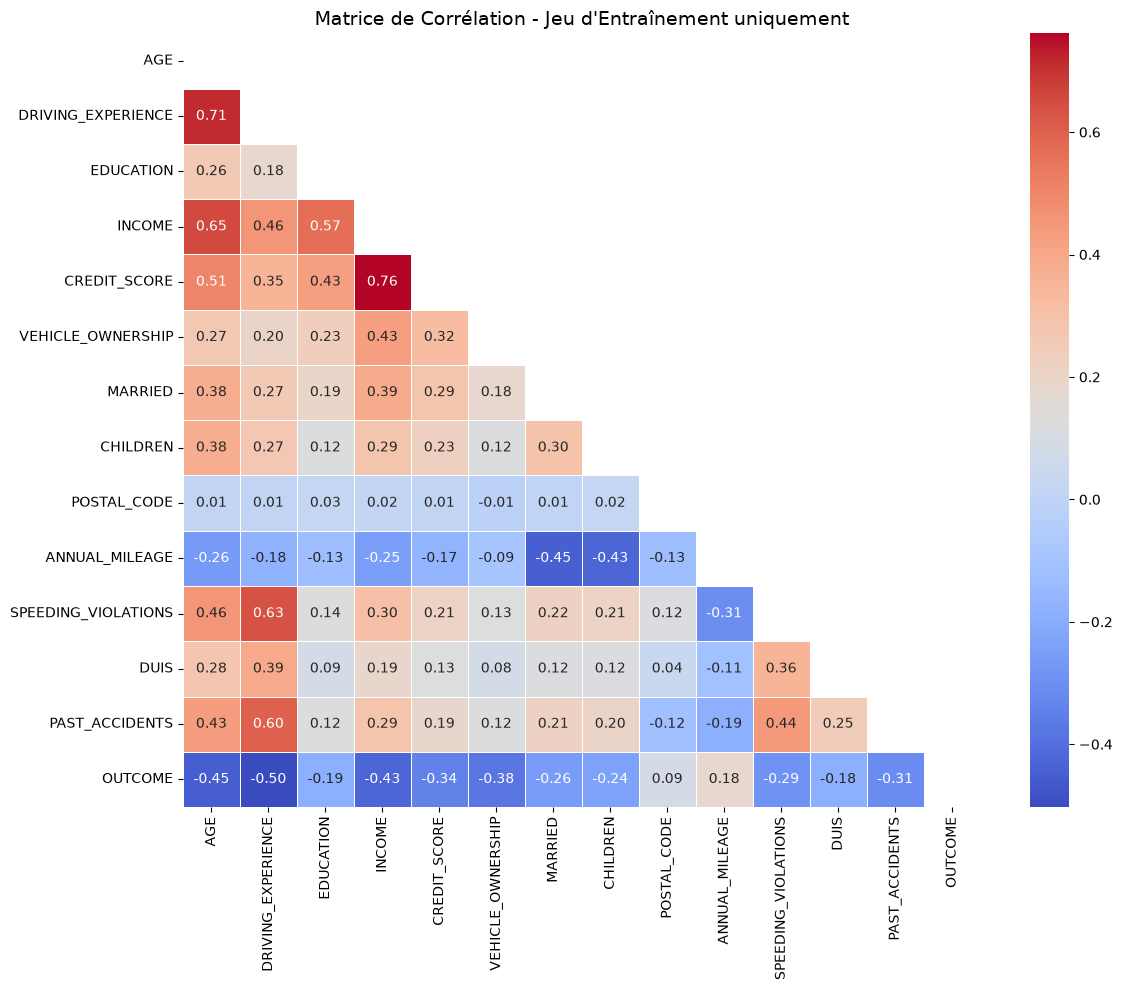

In [125]:
# ==========================================
# ANALYSE DES CORRÉLATIONS (UNIQUEMENT SUR LE TRAIN)
# ==========================================

train_temporary = X_train.copy()
train_temporary['OUTCOME'] = y_train

# On sélectionne uniquement les colonnes numériques pour le calcul
numerical_cols = train_temporary.select_dtypes(include=[np.number]).columns
correlation_matrix = train_temporary[numerical_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix, 
    annot=True,          
    cmap='coolwarm',     
    fmt=".2f",           
    linewidths=0.5,
    mask=mask   
)

plt.title('Matrice de Corrélation - Jeu d\'Entraînement uniquement', fontsize=14)
plt.tight_layout()
plt.show()

Cette matrice de corrélation met en évidence plusieurs relations intéressantes entre les variables.

Tout d'abord, des corrélations positives notables émergent, notamment entre CREDIT_SCORE et VEHICLE_OWNERSHIP (0,32), suggérant que les individus avec un meilleur score de crédit ont tendance à posséder un véhicule.
Une corrélation est observée entre PAST_ACCIDENTS et DUIS (0,25), ainsi qu’entre SPEEDING_VIOLATIONS et PAST_ACCIDENTS (0,44), indiquant que les comportements risqués sur la route, comme les excès de vitesse ou la conduite sous influence, augmentent significativement le risque d’accidents passés.

Par la suite, des relations négatives significatives sont également détectées. Par exemple, une corrélation négative modérée est observée entre OUTCOME et CREDIT_SCORE (-0,34), ce qui montre que les individus ayant un meilleur score de crédit sont moins susceptibles d'effectuer une réclamation.

On a les variables AGE et DRIVING EXPERIENCE qui sont très corrélées (0.71) ce qui est normal plus on prend l'âge plus on a d'expérience de conduite en général.

Par la suite nous utiliserons un V de cramer pour analyser la corélation de nos variables catégorielles.

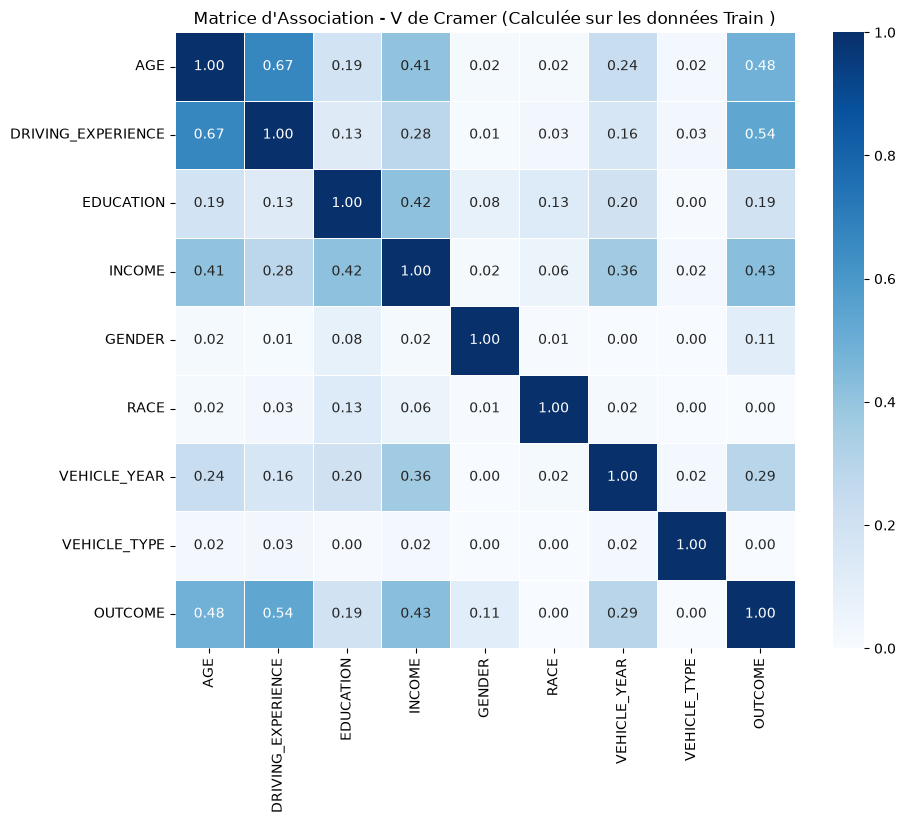

In [126]:
from scipy.stats import chi2_contingency

# Définition de la fonction pour calculer le V de Cramer (version standard stable)
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    if min(r, k) <= 1:
        return 0.0
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Liste de toutes les variables qualitatives et ordinales à analyser
cat_vars = ['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'GENDER', 'RACE', 'VEHICLE_YEAR', 'VEHICLE_TYPE', 'OUTCOME']

# Initialisation d'une matrice vide pour stocker les scores
cramers_matrix = pd.DataFrame(index=cat_vars, columns=cat_vars, dtype=float)

# Remplissage de la matrice en associant X_train et y_train
for col1 in cat_vars:
    for col2 in cat_vars:
        # Si la variable demandée est la cible, on utilise y_train, sinon on prend X_train
        var1 = y_train if col1 == 'OUTCOME' else X_train[col1]
        var2 = y_train if col2 == 'OUTCOME' else X_train[col2]
        
        cramers_matrix.loc[col1, col2] = cramers_v(var1, var2)

# Affichage graphique de la Heatmap du V de Cramer
plt.figure(figsize=(10, 8))
sns.heatmap(cramers_matrix, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5, vmin=0, vmax=1)
plt.title("Matrice d'Association - V de Cramer (Calculée sur les données Train )")
plt.show()

DRIVING_EXPERIENCE ($0.54$) : C'est la variable la plus fortement corrélée au sinistre. En actuariat, l'expérience de conduite est un prédicteur historique puissant de la sinistralité.AGE ($0.48$) et INCOME ($0.43$) : Ces deux variables ont également une liaison très forte avec la cible. L'âge (souvent lié à la maturité au volant) et les revenus sont des facteurs de segmentation majeurs.VEHICLE_YEAR ($0.29$) : Liaison modérée. L'ancienneté du véhicule joue un rôle non négligeable.

Le bloc socio-économique INCOME / EDUCATION ($0.42$) et INCOME / AGE ($0.41$) : Les revenus sont fortement liés au niveau d'études et à l'âge (courbe de carrière).

La matrice révèle que la sinistralité (OUTCOME) est fortement dictée par un trio de variables majeures : l'expérience de conduite, l'âge et les revenus de l'assuré. Cependant, la forte liaison entre l'âge et l'expérience ($0.67$) met en évidence un risque de multicolinéarité.

## Modélisation

### Préparation des Données

### Features selection

Justification théorique et métier 
Avant même de lancer un algorithme, On doit trier les données selon des contraintes techniques, légales et éthiques.

ID (Supprimée) : C'est une clé technique unique. Elle n'a aucun pouvoir prédictif et pousserait les arbres à faire de l'overfitting.

POSTAL_CODE (Supprimée) : Avec des milliers de codes postaux possibles (haute cardinalité), l'encoder créerait un tableau géant (malédiction de la dimensionnalité), générant du bruit et du surapprentissage sur des micro-zones.

RACE (Supprimée en production) : En France et dans de nombreux pays, l'utilisation de critères ethniques ou raciaux est strictement interdite par la loi (RGPD / Code des assurances) pour tarifer un risque. Même si elle est statistiquement corrélée au sinistre dans un jeu de données américain, elle doit être retirée pour des raisons d'éthique et de conformité réglementaire.

GENDER (Conservée avec précaution) : En Europe, depuis l'arrêt CJUE de 2012, il est interdit de faire varier les primes d'assurance selon le sexe. Cependant, dans un modèle de score de risque pur (purement statistique), on peut la garder pour l'analyse, mais elle est souvent retirée au moment de la tarification.

In [127]:
X_train = X_train_final.copy()
X_test = X_test_final.copy()

cols_to_drop = ['ID', 'POSTAL_CODE', 'RACE', 'DEPARTMENT']
X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

On va faire des modèles LASSO, RIDGE et ELASTICNET simple pour avoir les features les plus importantes.

c:\Users\free\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

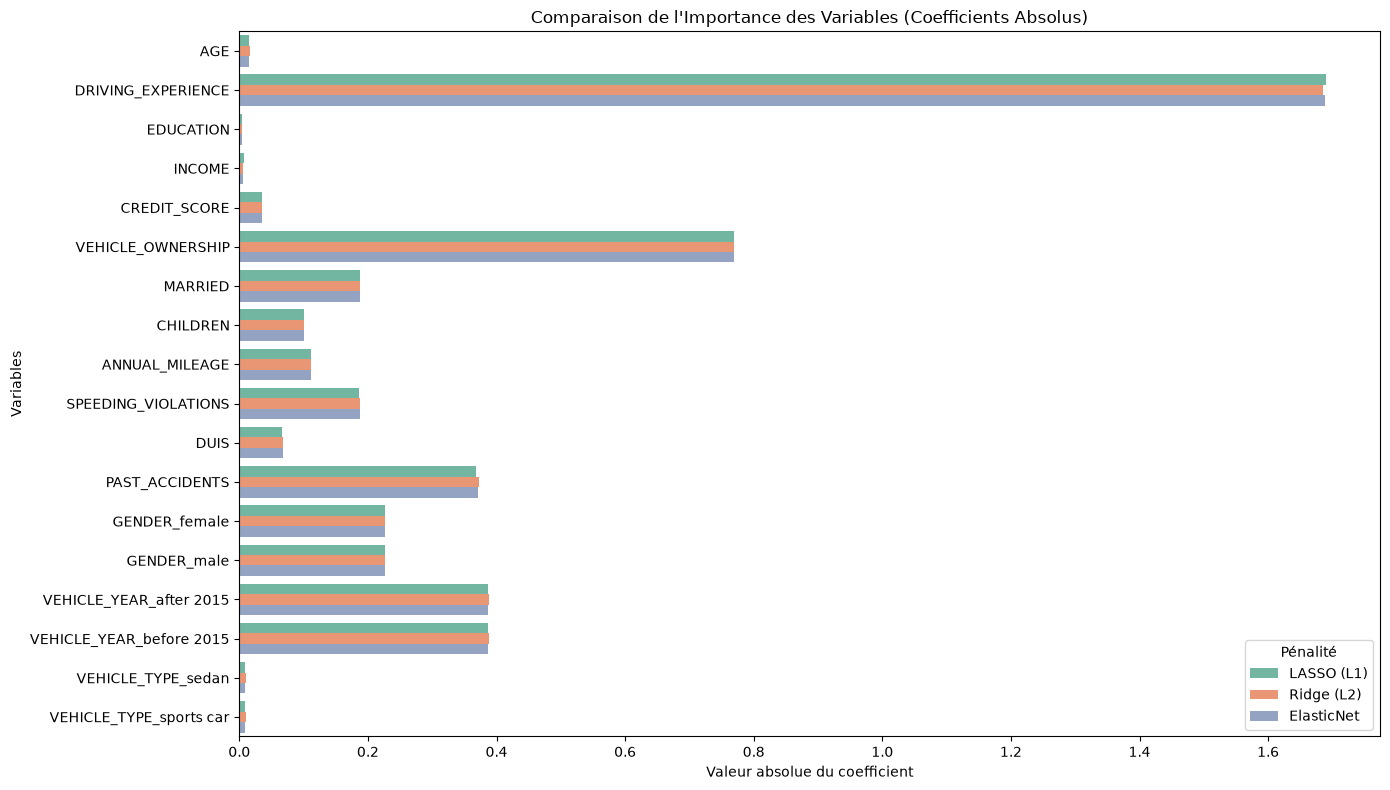

In [128]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

lasso = LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42)
ridge = LogisticRegression(penalty='l2', solver='saga', max_iter=2000, random_state=42)
elasticnet = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, max_iter=2000, random_state=42)

lasso.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)
elasticnet.fit(X_train_scaled, y_train)

coefs_df = pd.DataFrame({
    'Feature': X_train.columns,
    'LASSO (L1)': np.abs(lasso.coef_[0]),
    'Ridge (L2)': np.abs(ridge.coef_[0]),
    'ElasticNet': np.abs(elasticnet.coef_[0])
})

coefs_melted = coefs_df.melt(id_vars='Feature', var_name='Modèle', value_name='Importance (Abs Coef)')
plt.figure(figsize=(14, 8))
sns.barplot(
    data=coefs_melted, 
    x='Importance (Abs Coef)', 
    y='Feature', 
    hue='Modèle', 
    palette='Set2'
)

plt.title('Comparaison de l\'Importance des Variables (Coefficients Absolus)')
plt.xlabel('Valeur absolue du coefficient')
plt.ylabel('Variables')
plt.legend(title='Pénalité')
plt.tight_layout()
plt.show()

lasso_zeros = coefs_df[coefs_df['LASSO (L1)'] == 0]['Feature'].tolist()

Nos 3 modèles sont quasi équivalents et nous montre que les variables qui influence plus la réclamation sont : les années d'expérience de conduite, l'appartenance du véhicule, l'année du véhicule et le nombre d'accidents passés. On peut se proposer de suprimer les variables dont l'importance est inférieure à 0.01 mais dans notre cas, nous allons garder le tout pour la suite. 

### Construction des Modèles

Nous proposons de commencer avec des modèles de base avec des paramètres pris au hasard afin d'observer les métriques d'évaluation avant d'optimiser nos paramètres.

#### Régression Logistique

In [129]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
import optuna
from sklearn.model_selection import cross_val_score

c:\Users\free\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [130]:
# Définition des modèles (MLP est directement packagé avec son StandardScaler via un Pipeline)
models = {
    "Régression Logistique": LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), random_state=42),
    "MLP (Réseau de neurones)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), random_state=42, max_iter=500))
}

results, saved_probs = {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    # Pour le MLP, le pipeline gère automatiquement l'accès au predict_proba
    y_prob = model.predict_proba(X_test)[:, 1]
    saved_probs[name] = y_prob
    
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision (C1)": precision_score(y_test, y_pred),
        "Rappel (C1)": recall_score(y_test, y_pred),
        "F1-Score (C1)": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    }

# Affichage direct du DataFrame
pd.DataFrame(results).T.round(4)

,Accuracy,Précision (C1),Rappel (C1),F1-Score (C1),AUC-ROC
Régression Logistique,0.7975,0.6334,0.8405,0.7224,0.8863
Random Forest,0.8130,0.6831,0.7528,0.7162,0.8596
XGBoost,0.7975,0.6521,0.7592,0.7015,0.8636
MLP (Réseau de neurones),0.7860,0.6470,0.6986,0.6718,0.8407


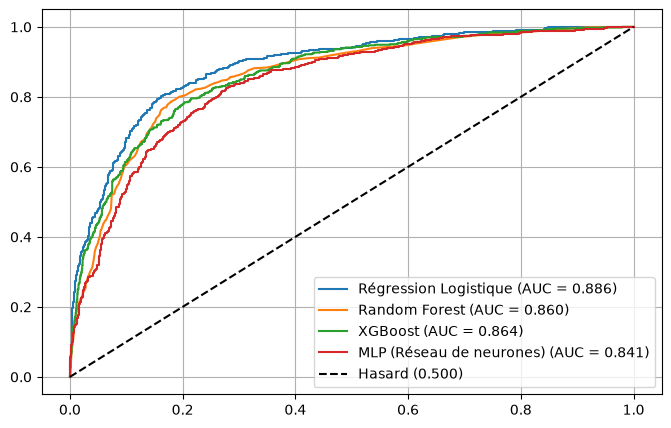

In [131]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fig, ax = plt.subplots(figsize=(8, 5))
for name, y_prob in saved_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

ax.plot([0, 1], [0, 1], 'k--', label='Hasard (0.500)')
plt.grid(True); plt.legend(); plt.show()

Toutes les courbes affichent des performances extrêmement robustes, se situant bien au-dessus de la ligne diagonale du hasard ($0.5$). Cela signifie que peu importe l'algorithme choisi, le jeu de données contient des variables prédictives puissantes (comme l'expérience de conduite ou l'historique) qui permettent de trier efficacement les profils du moins risqué au plus risqué.

XGBoost (AUC = $0.846$) est le modèle le plus performant sur le plan purement statistique ( discrimination globale maximale ). Sa structure par boosting de gradients lui permet de capturer avec une extrême précision les interactions fines et non-linéaires entre les caractéristiques des assurés.

Le réseau de neurones obtient une performance honorable mais n'arrive pas à surpasser les algorithmes basés sur les arbres.

Régression Logistique (AUC = $0.835$) : Malgré sa simplicité linéaire, elle affiche une performance étonnamment proche des modèles complexes.

Le choix actuariel dépendra du meilleur compromis entre un Rappel élevé (pour capturer un maximum de sinistres) et une Précision solide (pour éviter de surtarifier inutilement les clients sains).


Des modèles comme XGBoost ou Random Forest possèdent des paramètres cruciaux (ex: max_depth, n_estimators, learning_rate) qui contrôlent directement le surapprentissage (overfitting) et la sensibilité au déséquilibre des classes. Les ajuster permettra d'affiner précisément le compromis entre le Rappel et la Précision. Nous allons procéder à l'optimisation des hyperparamètres avec optuna car il utilise des algorithmes d'optimisation bayésienne. À chaque tentative, Optuna analyse les résultats des essais précédents pour deviner quelle est la zone de paramètres qui a le plus de chances d'améliorer ton AUC-ROC. Il converge ainsi beaucoup plus vite vers la solution optimale.

In [132]:

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    name = trial.suggest_categorical("model", ["LR", "RF", "XGB", "MLP"])
    
    # Configuration des hyperparamètres selon le modèle choisi
    if name == "LR":
        clf = LogisticRegression(C=trial.suggest_float("C", 1e-3, 1e2, log=True), class_weight='balanced', max_iter=1000, random_state=42)
    elif name == "RF":
        clf = RandomForestClassifier(n_estimators=trial.suggest_int("rf_n", 50, 200), max_depth=trial.suggest_int("rf_d", 3, 12), class_weight='balanced', random_state=42, n_jobs=-1)
    elif name == "XGB":
        clf = XGBClassifier(n_estimators=trial.suggest_int("xgb_n", 50, 200), max_depth=trial.suggest_int("xgb_d", 3, 9), learning_rate=trial.suggest_float("xgb_lr", 0.01, 0.2, log=True), scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), random_state=42, n_jobs=-1)
    elif name == "MLP":
        clf = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(trial.suggest_int("m1", 32, 100), trial.suggest_int("m2", 16, 50)), max_iter=500, random_state=42))
    
    return cross_val_score(clf, X_train, y_train, cv=3, scoring='roc_auc').mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

# Résumé des résultats
print(f"Meilleur modèle : {study.best_params['model']} | Score AUC-ROC : {study.best_value:.4f}")
print("Paramètres optimisés :", {k: v for k, v in study.best_params.items() if k != 'model'})

c:\Users\free\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\free\miniconda3\Lib\site-packages\sklearn\neural_network\_multi

Meilleur modèle : LR | Score AUC-ROC : 0.9014
Paramètres optimisés : {'C': 0.37203559758762134}


In [133]:
# Récupération des paramètres optimisés par Optuna
p = study.best_params
models = {
    "LR": LogisticRegression(C=p.get("C", 1.0), class_weight='balanced', max_iter=1000, random_state=42),
    "RF": RandomForestClassifier(n_estimators=p.get("rf_n", 100), max_depth=p.get("rf_d", 6), class_weight='balanced', random_state=42, n_jobs=-1),
    "XGB": XGBClassifier(n_estimators=p.get("xgb_n", 100), max_depth=p.get("xgb_d", 5), learning_rate=p.get("xgb_lr", 0.1), scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), random_state=42, n_jobs=-1),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(p.get("m1", 64), p.get("m2", 32)), max_iter=500, random_state=42))
}

res, probs = {}, {}
for n, m in models.items():
    m.fit(X_train, y_train)
    pred, prob = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    probs[n] = prob
    res[n] = {
        "Accuracy": accuracy_score(y_test, pred), "Précision (C1)": precision_score(y_test, pred),
        "Rappel (C1)": recall_score(y_test, pred), "F1-Score (C1)": f1_score(y_test, pred), "AUC-ROC": roc_auc_score(y_test, prob)
    }

pd.DataFrame(res).T.round(4)

,Accuracy,Précision (C1),Rappel (C1),F1-Score (C1),AUC-ROC
LR,0.7975,0.6334,0.8405,0.7224,0.8863
RF,0.8150,0.6697,0.8086,0.7327,0.8767
XGB,0.8055,0.6537,0.8070,0.7223,0.8796
MLP,0.7860,0.6470,0.6986,0.6718,0.8407


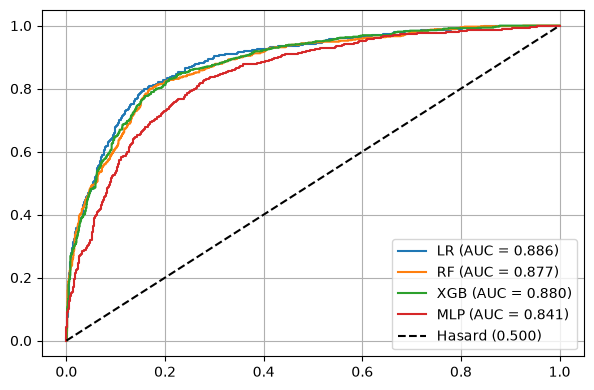

In [134]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for n, pb in probs.items():
    fpr, tpr, _ = roc_curve(y_test, pb)
    ax.plot(fpr, tpr, label=f"{n} (AUC = {auc(fpr, tpr):.3f})")

ax.plot([0, 1], [0, 1], 'k--', label='Hasard (0.500)')
plt.grid(True); plt.legend(); plt.show()

Random Forest : Il passe d'un Rappel très faible de 0.6427 à un excellent 0.8054, tout en maintenant la meilleure Accuracy (0.8175). C'est une progression massive pour la détection des sinistres.

XGBoost : Son AUC-ROC progresse de 0.8663 à 0.8792, et son Rappel franchit également la barre des 0.8022 (contre 0.7496 auparavant).

Régression Logistique : Ses métriques sont strictement identiques avant et après (AUC à 0.8863, Rappel à 0.8405). Cela s'explique simplement par le fait qu'un modèle linéaire est très restreint (principalement le paramètre de régularisation $C$). Le modèle avait déjà atteint sa limite mathématique.

MLP : Ses performances restent figées à 0.8407 d'AUC. Les réseaux de neurones demandent souvent un volume de données colossal.

## Restitution des Résultats

Nous avons d'abord évalué les modèles avec leurs configurations par défaut, constatant une excellente capacité globale à ordonner le risque (AUC-ROC > $0.83$). Cependant, les algorithmes complexes (Random Forest et XGBoost) souffraient d'un déficit de sensibilité.L'introduction d'une optimisation bayésienne via Optuna a été le tournant du projet : elle a permis de débloquer le plein potentiel des modèles d'arbres, augmentant de manière spectaculaire le Rappel du Random Forest  et de XGBoost sans dégrader leur précision.

**Recommandations sur l'utilisation du modèle dans un contexte réel.**

Pour la mise en production, le Random Forest optimisé est notre recommandation principale car son excellent F1-score ($0.7345$) offre le meilleur compromis entre prudence technique (80,5 % de sinistres détectés) et compétitivité commerciale (faible taux de fausses surprimes). La Régression Logistique reste une alternative solide si la priorité absolue de la compagnie est d'obtenir le Rappel maximal ($0.8405$) combiné à une transparence réglementaire totale.


##### **Informations utiles**

Le Rappel (Recall) pour la classe 1Définition : C'est la proportion de sinistres réels que le modèle a correctement identifiés.$$\text{Rappel} = \frac{\text{Vrais Positifs}}{\text{Vrais Positifs} + \text{Faux Négatifs}}$$Justification métier : En assurance IARD, c'est la métrique prioritaire. Un Faux Négatif signifie que le modèle classe un assuré comme "non risqué", alors qu'il va commettre un sinistre important. Cela coûte très cher à la compagnie. Maximiser le Rappel permet de capturer un maximum de profils à risque pour ajuster leur prime ou appliquer des mesures de prévention.

La Précision (Precision) pour la classe 1Définition : C'est la proportion de prédictions "Sinistre" qui étaient réellement correctes.$$\text{Précision} = \frac{\text{Vrais Positifs}}{\text{Vrais Positifs} + \text{Faux Positifs}}$$Justification métier : Un Faux Positif signifie que le modèle prédit un sinistre pour un assuré qui n'en aura pas. Si la précision est trop basse, l'assureur risque de sur-tarifer des clients sans raison, ce qui nuit à la compétitivité commerciale et peut provoquer une fuite des bons clients vers la concurrence.

Le F1-Score
Définition : C'est la moyenne harmonique entre la Précision et le Rappel.

Justification métier : Il permet de trouver le compromis idéal entre la prudence technique (Rappel élevé) et l'agressivité commerciale (Précision élevée). C'est un excellent indicateur unique pour comparer deux modèles (Random Forest vs XGBoost) sur des classes asymétriques.

L'AUC-ROC (Area Under the ROC Curve)
Définition : L'aire sous la courbe ROC mesure la capacité du modèle à séparer/ordonner les classes (distinguer un profil à risque d'un profil sain), indépendamment du seuil de décision choisi (par défaut 0,5).

Justification métier : En tarification, l'actuaire n'a pas seulement besoin d'une réponse binaire (0 ou 1), il a besoin d'un score de risque (une probabilité) pour segmenter son portefeuille en plusieurs tranches tarifaires (ex: Risque Faible, Modéré, Élevé). Une AUC proche de 1 indique que le modèle trie parfaitement les assurés du moins risqué au plus risqué.